In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt


# EDA — исследовательский анализ данных

In [2]:
df = pd.read_csv("./data/Task1_l6s.csv", sep=';', encoding='utf-8')
display(df.head())

,id,id_session,stage,time_end
0,1,1,Поступление заявки на установку оборудования,01.02.2024 10:00
1,2,1,Рассмотрение заявки менеджером,01.02.2024 11:00
2,3,1,Рассмотрение заявки менеджером,01.02.2024 12:00
3,4,1,Рассмотрение заявки менеджером,01.02.2024 13:00
4,5,1,Рассмотрение заявки инженером,01.02.2024 14:00


In [3]:
df = pd.DataFrame(df)

df["time_end"] = pd.to_datetime(df["time_end"], format="%d.%m.%Y %H:%M")

df = df.sort_values(["id_session", "time_end"])

df["duration"] = df.groupby("id_session")["time_end"].diff().dt.total_seconds() / 3600

case_total = df.groupby("id_session")["duration"].sum().reset_index()

print("DataFrame shape:", df.shape)
print("isnull count:", df.isnull().sum())
print("negative duration count:", (df["duration"] < 0).sum())
print("case_total:\n", case_total)


df

DataFrame shape: (1703, 5)
isnull count: id              0
id_session      0
stage           0
time_end        0
duration      133
dtype: int64
negative duration count: 0
case_total:
      id_session  duration
0             1      16.1
1             2      18.0
2             3      19.4
3             4      17.5
4             5      37.0
..          ...       ...
128         129      19.4
129         130      17.6
130         131      16.2
131         132      25.0
132         133      18.6

[133 rows x 2 columns]


,id,id_session,stage,time_end,duration
0,1,1,Поступление заявки на установку оборудования,2024-02-01 10:00:00,NaN
1,2,1,Рассмотрение заявки менеджером,2024-02-01 11:00:00,1.0
2,3,1,Рассмотрение заявки менеджером,2024-02-01 12:00:00,1.0
3,4,1,Рассмотрение заявки менеджером,2024-02-01 13:00:00,1.0
4,5,1,Рассмотрение заявки инженером,2024-02-01 14:00:00,1.0
...,...,...,...,...,...
1698,1699,133,Согласование заявки бухгалером,2024-03-14 21:24:00,3.0
1699,1700,133,Получение оборудования на складе,2024-03-15 03:24:00,6.0
1700,1701,133,Выезд к клиенту,2024-03-15 04:24:00,1.0
1701,1702,133,Оборудование успешно установлено,2024-03-15 05:24:00,1.0


In [4]:

case_total.describe()

,id_session,duration
count,133.00000,133.000000
mean,67.00000,29.931579
std,38.53786,99.486478
min,1.00000,16.100000
25%,34.00000,18.600000
50%,67.00000,20.000000
75%,100.00000,22.000000
max,133.00000,1167.100000


In [5]:
stage_stats = df.groupby("stage")["duration"].agg(["mean", "median", "sum","min", "max", "count"]).reset_index()
display(stage_stats.sort_values("sum", ascending=False).reset_index(drop=True))

,stage,mean,median,sum,min,max,count
0,Выезд к клиенту,9.654135,1.0,1284.0,1.0,1152.0,133
1,Получение оборудования на складе,6.000000,6.0,858.0,6.0,6.0,143
2,Согласование заявки бухгалером,3.916084,4.0,560.0,1.0,7.0,143
3,Рассмотрение заявки менеджером,1.000000,1.0,429.0,1.0,1.0,429
4,Формирование отчета о выезде,1.660902,1.7,220.9,1.1,2.0,133
5,Согласование заявки инженером,1.279720,1.0,183.0,1.0,5.0,143
6,Рассмотрение заявки инженером,1.000000,1.0,143.0,1.0,1.0,143
7,Оборудование успешно установлено,1.000000,1.0,133.0,1.0,1.0,133
8,Согласование заявки юристом,1.000000,1.0,72.0,1.0,1.0,72
9,Назначение материалоответственного,1.000000,1.0,71.0,1.0,1.0,71


In [6]:
outliers = df[df["stage"] == "Выезд к клиенту"].sort_values("duration", ascending=False).head(1)
display(outliers)

,id,id_session,stage,time_end,duration
244,245,19,Выезд к клиенту,2024-07-21 16:48:00,1152.0


In [7]:
bad_sessions = df[df["id_session"].isin(outliers["id_session"])]
bad_sessions

,id,id_session,stage,time_end,duration
235,236,19,Поступление заявки на установку оборудования,2024-06-03 03:48:00,NaN
236,237,19,Рассмотрение заявки менеджером,2024-06-03 04:48:00,1.0
237,238,19,Рассмотрение заявки менеджером,2024-06-03 05:48:00,1.0
238,239,19,Рассмотрение заявки менеджером,2024-06-03 06:48:00,1.0
239,240,19,Рассмотрение заявки инженером,2024-06-03 07:48:00,1.0
240,241,19,Согласование заявки инженером,2024-06-03 08:48:00,1.0
241,242,19,Согласование заявки юристом,2024-06-03 09:48:00,1.0
242,243,19,Согласование заявки бухгалером,2024-06-03 10:48:00,1.0
243,244,19,Получение оборудования на складе,2024-06-03 16:48:00,6.0
244,245,19,Выезд к клиенту,2024-07-21 16:48:00,1152.0


In [8]:
df["prev_time"] = df.groupby("id_session")["time_end"].shift(1)
df["day_cross"] = (df["prev_time"].notna()) & (df["time_end"].dt.date != df["prev_time"].dt.date)

display(df[df["id_session"] == 19])
display(df[df["id_session"] == 10])

,id,id_session,stage,time_end,duration,prev_time,day_cross
235,236,19,Поступление заявки на установку оборудования,2024-06-03 03:48:00,NaN,NaT,False
236,237,19,Рассмотрение заявки менеджером,2024-06-03 04:48:00,1.0,2024-06-03 03:48:00,False
237,238,19,Рассмотрение заявки менеджером,2024-06-03 05:48:00,1.0,2024-06-03 04:48:00,False
238,239,19,Рассмотрение заявки менеджером,2024-06-03 06:48:00,1.0,2024-06-03 05:48:00,False
239,240,19,Рассмотрение заявки инженером,2024-06-03 07:48:00,1.0,2024-06-03 06:48:00,False
240,241,19,Согласование заявки инженером,2024-06-03 08:48:00,1.0,2024-06-03 07:48:00,False
241,242,19,Согласование заявки юристом,2024-06-03 09:48:00,1.0,2024-06-03 08:48:00,False
242,243,19,Согласование заявки бухгалером,2024-06-03 10:48:00,1.0,2024-06-03 09:48:00,False
243,244,19,Получение оборудования на складе,2024-06-03 16:48:00,6.0,2024-06-03 10:48:00,False
244,245,19,Выезд к клиенту,2024-07-21 16:48:00,1152.0,2024-06-03 16:48:00,True


,id,id_session,stage,time_end,duration,prev_time,day_cross
118,119,10,Поступление заявки на установку оборудования,2024-03-29 02:24:00,NaN,NaT,False
119,120,10,Рассмотрение заявки менеджером,2024-03-29 03:24:00,1.0,2024-03-29 02:24:00,False
120,121,10,Рассмотрение заявки менеджером,2024-03-29 04:24:00,1.0,2024-03-29 03:24:00,False
121,122,10,Рассмотрение заявки менеджером,2024-03-29 05:24:00,1.0,2024-03-29 04:24:00,False
122,123,10,Рассмотрение заявки инженером,2024-03-29 06:24:00,1.0,2024-03-29 05:24:00,False
123,124,10,Согласование заявки инженером,2024-03-29 07:24:00,1.0,2024-03-29 06:24:00,False
124,125,10,Согласование заявки бухгалером,2024-03-29 11:24:00,4.0,2024-03-29 07:24:00,False
125,126,10,Назначение материалоответственного,2024-03-29 12:24:00,1.0,2024-03-29 11:24:00,False
126,127,10,Получение оборудования на складе,2024-03-29 18:24:00,6.0,2024-03-29 12:24:00,False
127,128,10,Выезд к клиенту,2024-03-29 19:24:00,1.0,2024-03-29 18:24:00,False


In [9]:
stage_median = df[~df["day_cross"]].groupby("stage")["duration"].median().reset_index().rename(columns={"duration": "stage_median"})

df = df.merge(stage_median, on="stage", how="left")

df.loc[df["duration"] == 1152.0, "duration"] = df["stage_median"]

print(stage_median)
df

                                           stage  stage_median
0                                Выезд к клиенту           1.0
1             Назначение материалоответственного           1.0
2               Оборудование успешно установлено           1.0
3               Получение оборудования на складе           6.0
4   Поступление заявки на установку оборудования           1.0
5      Проверка перечня наминклатуры бухгалтером           1.0
6                  Рассмотрение заявки инженером           1.0
7                 Рассмотрение заявки менеджером           1.0
8                 Согласование заявки бухгалером           4.0
9                  Согласование заявки инженером           1.0
10                   Согласование заявки юристом           1.0
11                  Формирование отчета о выезде           1.7


,id,id_session,stage,time_end,duration,prev_time,day_cross,stage_median
0,1,1,Поступление заявки на установку оборудования,2024-02-01 10:00:00,NaN,NaT,False,1.0
1,2,1,Рассмотрение заявки менеджером,2024-02-01 11:00:00,1.0,2024-02-01 10:00:00,False,1.0
2,3,1,Рассмотрение заявки менеджером,2024-02-01 12:00:00,1.0,2024-02-01 11:00:00,False,1.0
3,4,1,Рассмотрение заявки менеджером,2024-02-01 13:00:00,1.0,2024-02-01 12:00:00,False,1.0
4,5,1,Рассмотрение заявки инженером,2024-02-01 14:00:00,1.0,2024-02-01 13:00:00,False,1.0
...,...,...,...,...,...,...,...,...
1698,1699,133,Согласование заявки бухгалером,2024-03-14 21:24:00,3.0,2024-03-14 18:24:00,False,4.0
1699,1700,133,Получение оборудования на складе,2024-03-15 03:24:00,6.0,2024-03-14 21:24:00,True,6.0
1700,1701,133,Выезд к клиенту,2024-03-15 04:24:00,1.0,2024-03-15 03:24:00,False,1.0
1701,1702,133,Оборудование успешно установлено,2024-03-15 05:24:00,1.0,2024-03-15 04:24:00,False,1.0


In [10]:
display(df[df["day_cross"] == True])


,id,id_session,stage,time_end,duration,prev_time,day_cross,stage_median
9,10,1,Выезд к клиенту,2024-02-02 00:00:00,1.0,2024-02-01 23:00:00,True,1.0
33,34,3,Получение оборудования на складе,2024-02-28 04:36:00,6.0,2024-02-27 22:36:00,True,6.0
40,41,4,Рассмотрение заявки менеджером,2024-03-07 00:48:00,1.0,2024-03-06 23:48:00,True,1.0
50,51,5,Рассмотрение заявки менеджером,2024-05-10 00:48:00,1.0,2024-05-09 23:48:00,True,1.0
64,65,5,Согласование заявки бухгалером,2024-05-11 01:48:00,4.0,2024-05-10 21:48:00,True,4.0
...,...,...,...,...,...,...,...,...
1649,1650,129,Согласование заявки бухгалером,2024-03-02 01:12:00,4.0,2024-03-01 21:12:00,True,4.0
1661,1662,130,Согласование заявки бухгалером,2024-03-14 00:48:00,2.0,2024-03-13 22:48:00,True,4.0
1671,1672,131,Рассмотрение заявки инженером,2024-02-15 00:18:00,1.0,2024-02-14 23:18:00,True,1.0
1687,1688,132,Получение оборудования на складе,2024-05-27 02:48:00,6.0,2024-05-26 20:48:00,True,6.0



### **Результаты EDA**

**Общая информация.** В датасете 1703 записи, 133 кейса (`id_session`) и 12 этапов обработки заявки. Длительность этапа рассчитана как разница между соседними отметками времени внутри кейса и выражена в часах:

$$\Delta t_i = t_i - t_{i-1}$$

Пропуски есть только в рассчитанной длительности — 133 значения (по одному на кейс: у первого этапа нет предыдущей отметки); в исходных данных пропусков нет. Нулевых и отрицательных длительностей не обнаружено, минимальная длительность — 1 час. Полных дубликатов строк нет. Обнаружены 2 опечатки в исходных названиях этапов («Согласование заявки бухгалером», «Проверка перечня наминклатуры бухгалтером»). Названия сохранены как есть, чтобы не потерять связь с исходником.

**Выявленные аномалии.**
1. Экстремальный выброс: кейс №19, этап «Выезд к клиенту» — 1152 часа (48 суток). Время суток начала и конца интервала совпадает (16:48), что указывает на искусственную задержку в генерации лога. Причина указана как предположение, так как отдельного признака причины в данных нет. Выброс сильно искажает статистику: среднее время кейса — 29,9 ч при медиане 20,0 ч, максимальное время кейса — 1167,1 ч.
2. Переходы через календарные сутки: у 118 записей (6,9 %) в 112 кейсах из 133 предыдущая отметка времени приходится на другой день, поэтому в длительность попадает ночной простой и ожидание. Эти записи не заменялись, так как разделить работу, ожидание и ночной простой по имеющимся данным нельзя. Переходы помечены флагом `day_cross` для отдельного анализа.

**Результат очистки.** Заменена 1 запись — выброс в кейсе №19 заменён медианой этапа (1,0 ч). Суммарная длительность снизилась с 3980,9 до 2829,9 ч. Время кейса №19 — с 1167,1 до 16,1 ч, максимальное время кейса — с 1167,1 до 43,0 ч. Среднее время кейса уменьшилось с 29,9 до 21,3 ч, медиана — с 20,0 до 19,9 ч.

**Ограничение.** Длительность рассчитана только по `time_end`, поэтому она включает Service Time + Waiting Time + ночной простой. Разделить их по имеющимся данным невозможно.


# EDA — восстановление схемы процесса и анализ маршрутов и поиск структурных потерь

In [39]:

df2 = df.copy()
df2 = df2.sort_values(["id_session", "time_end"])
variants = df2.groupby("id_session")["stage"].apply(tuple)
variants_counts = variants.value_counts()


for i, (_, row) in enumerate(variants_counts.reset_index().iterrows(), start=1):
    route = " -> ".join(row["stage"]) 
    print(f"#{i} | Count: {row['count']} | Variant: {route}\n")

#1 | Count: 56 | Variant: Поступление заявки на установку оборудования -> Рассмотрение заявки менеджером -> Рассмотрение заявки менеджером -> Рассмотрение заявки менеджером -> Рассмотрение заявки инженером -> Согласование заявки инженером -> Согласование заявки юристом -> Согласование заявки бухгалером -> Получение оборудования на складе -> Выезд к клиенту -> Оборудование успешно установлено -> Формирование отчета о выезде

#2 | Count: 55 | Variant: Поступление заявки на установку оборудования -> Рассмотрение заявки менеджером -> Рассмотрение заявки менеджером -> Рассмотрение заявки менеджером -> Рассмотрение заявки инженером -> Согласование заявки инженером -> Согласование заявки бухгалером -> Назначение материалоответственного -> Получение оборудования на складе -> Выезд к клиенту -> Оборудование успешно установлено -> Формирование отчета о выезде

#3 | Count: 5 | Variant: Поступление заявки на установку оборудования -> Поступление заявки на установку оборудования -> Рассмотрение зая

In [12]:
last_stage = df.groupby("id_session")["stage"].last()
print(last_stage.value_counts())

stage
Формирование отчета о выезде    133
Name: count, dtype: int64


In [18]:
df["prev_stage"] = df.groupby("id_session")["stage"].shift(1)

dfg = (
df.dropna(subset=["prev_stage"])
   .groupby(["prev_stage", "stage"])
   .size()
   .reset_index(name="count")
)

dfg

,prev_stage,stage,count
0,Выезд к клиенту,Оборудование успешно установлено,133
1,Назначение материалоответственного,Получение оборудования на складе,71
2,Оборудование успешно установлено,Формирование отчета о выезде,133
3,Получение оборудования на складе,Выезд к клиенту,133
4,Получение оборудования на складе,Поступление заявки на установку оборудования,10
5,Поступление заявки на установку оборудования,Поступление заявки на установку оборудования,15
6,Поступление заявки на установку оборудования,Рассмотрение заявки менеджером,143
7,Проверка перечня наминклатуры бухгалтером,Назначение материалоответственного,1
8,Проверка перечня наминклатуры бухгалтером,Получение оборудования на складе,1
9,Рассмотрение заявки инженером,Согласование заявки инженером,143


In [14]:
p = variants_counts / variants_counts.sum()

entropy = -(p * np.log2(p)).sum()
print("Entropy of stage variants:", entropy)
print("Maximum possible entropy:", np.log2(len(variants_counts)))

Entropy of stage variants: 1.8701303920663823
Maximum possible entropy: 3.0


**прим.:** если энтропия близка к 0 — почти все кейсы идут по одному Happy Path. Это чистая «лазанья».
Если энтропия близка к максимуму — кейсы разбредаются равномерно по всем вариантам. Это «спагетти».
В данном случае энтропия расположенна по середине, такую структуру называют ветвящимся процессом. 

In [20]:
self_loops = dfg[dfg["prev_stage"] == dfg["stage"]].sort_values(
    "count", ascending=False
)
display(self_loops)


,prev_stage,stage,count
11,Рассмотрение заявки менеджером,Рассмотрение заявки менеджером,286
5,Поступление заявки на установку оборудования,Поступление заявки на установку оборудования,15


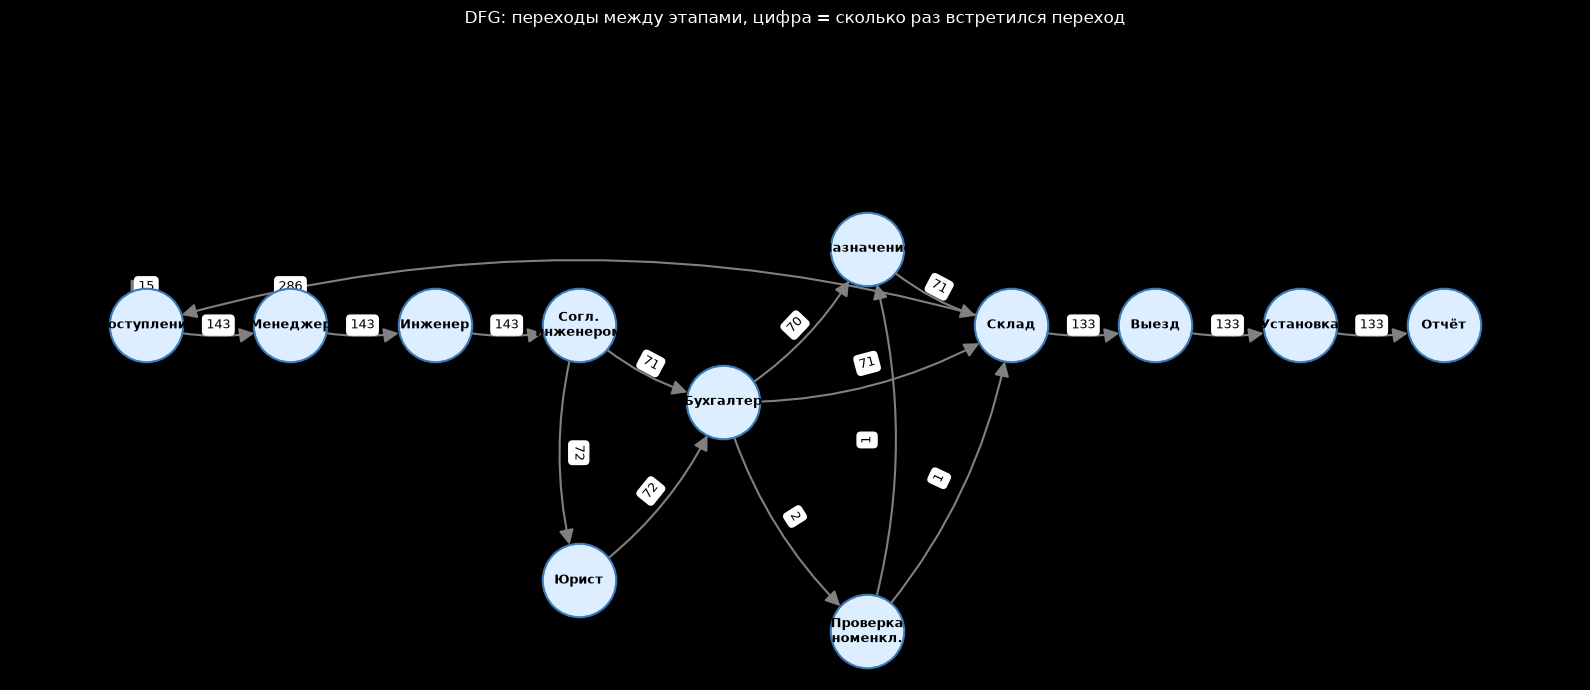

In [16]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Короткие названия, чтобы не налезали друг на друга
short = {
    "Поступление заявки на установку оборудования": "Поступление",
    "Рассмотрение заявки менеджером": "Менеджер",
    "Рассмотрение заявки инженером": "Инженер",
    "Согласование заявки инженером": "Согл.\nинженером",
    "Согласование заявки юристом": "Юрист",
    "Согласование заявки бухгалером": "Бухгалтер",
    "Проверка перечня наминклатуры бухгалтером": "Проверка\nноменкл.",
    "Назначение материалоответственного": "Назначение",
    "Получение оборудования на складе": "Склад",
    "Выезд к клиенту": "Выезд",
    "Оборудование успешно установлено": "Установка",
    "Формирование отчета о выезде": "Отчёт",
}

G = nx.DiGraph()
for _, row in dfg.iterrows():
    G.add_edge(short[row["prev_stage"]], short[row["stage"]], weight=row["count"])

# 2. Ручные позиции: x — шаг процесса слева направо, y — ветка вверх/вниз
#    Это самое главное исправление. Больше никакого spring_layout.
pos = {
    "Поступление": (0, 0),
    "Менеджер": (1, 0),
    "Инженер": (2, 0),
    "Согл.\nинженером": (3, 0),
    "Юрист": (3, -1.0),
    "Бухгалтер": (4, -0.3),
    "Проверка\nноменкл.": (5, -1.2),
    "Назначение": (5, 0.3),
    "Склад": (6, 0),
    "Выезд": (7, 0),
    "Установка": (8, 0),
    "Отчёт": (9, 0),
}

plt.figure(figsize=(16, 7))

# 3. Рисуем узлы
nx.draw_networkx_nodes(
    G, pos, node_size=2800, node_color="#DCEEFF", edgecolors="#3A7AB5", linewidths=1.5
)

# 4. Рисуем подписи узлов
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")

# 5. Рисуем стрелки. connectionstyle="arc3,rad=0.15" — стрелки чуть изогнуты,
#    поэтому Менеджер -> Менеджер не ляжет поверх основной линии, а уйдёт дугой вверх.
#    А Склад -> Поступление уйдёт дугой вниз и не перечеркнёт весь граф.
nx.draw_networkx_edges(
    G,
    pos,
    arrowsize=22,
    edge_color="gray",
    width=1.5,
    connectionstyle="arc3,rad=0.15",
    node_size=2800,
)

# 6. Цифры на стрелках — твой count из таблицы DFG
labels = {(u, v): d["weight"] for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=9, label_pos=0.5)

plt.title(
    "DFG: переходы между этапами, цифра = сколько раз встретился переход", fontsize=12
)
plt.axis("off")
plt.tight_layout()
plt.show()


# Выводы по анализу маршрутов и структурных потерь
Самоповторы: только 2 вида. Менеджер -> Менеджер (286) — норма процесса, но избыточная обработка: 3 раза вместо 1. Поступление -> Поступление (15) — дефект в 10 кейсах.

Пинг-понг $A \leftrightarrow B$: не обнаружен.

Глубокий возврат: Склад -> Поступление (10 кейсов). Это главная структурная потеря. Кейсы с возвратом длятся почти в 2 раза дольше. Причина в данных не указана, требует проверки регламента: почему кейс после склада возвращается в начало.

Мёртвые шаги: «Проверка перечня номенклатуры» (2 кейса, 1,5%) — не влияет на успех, 131 кейс финишировал без неё. «Юрист» и «Назначение» — не мёртвые, это XOR-ветвление.

Приоритет по 4 квадрантам: 1-е место — глубокий возврат, 2-е место — троекратный менеджер.

# Многоуровневая временная статистика

In [48]:
stage_stats = df.groupby("stage")["duration"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    min="min",
    p75=lambda x: x.quantile(0.75),
    p90=lambda x: x.quantile(0.90),
    max="max",
    sum_hours="sum",
)

stage_stats["share_pct"] = (
    stage_stats["sum_hours"] / stage_stats["sum_hours"].sum() * 100
)

display(stage_stats.sort_values("sum_hours", ascending=False).round(2))


,count,mean,median,std,min,p75,p90,max,sum_hours,share_pct
stage,,,,,,,,,,
Получение оборудования на складе,143,6.00,6.0,0.00,6.0,6.0,6.0,6.0,858.0,30.32
Согласование заявки бухгалером,143,3.92,4.0,1.83,1.0,5.0,7.0,7.0,560.0,19.79
Рассмотрение заявки менеджером,429,1.00,1.0,0.00,1.0,1.0,1.0,1.0,429.0,15.16
Формирование отчета о выезде,133,1.66,1.7,0.32,1.1,2.0,2.0,2.0,220.9,7.81
Согласование заявки инженером,143,1.28,1.0,1.02,1.0,1.0,1.0,5.0,183.0,6.47
Рассмотрение заявки инженером,143,1.00,1.0,0.00,1.0,1.0,1.0,1.0,143.0,5.05
Выезд к клиенту,133,1.00,1.0,0.00,1.0,1.0,1.0,1.0,133.0,4.70
Оборудование успешно установлено,133,1.00,1.0,0.00,1.0,1.0,1.0,1.0,133.0,4.70
Согласование заявки юристом,72,1.00,1.0,0.00,1.0,1.0,1.0,1.0,72.0,2.54


In [51]:
# 1. Мода — самое частое значение длительности во всём логе
print("Мода (самое частое значение):", df["duration"].mode().iloc[0])
print(
    "Сколько раз оно встречается:",
    (df["duration"] == 1.0).sum(),
    "из",
    df["duration"].count(),
)

# 2. Медиана медиан этапов — берём медиану каждого этапа, а потом медиану из них
#    Так мы не смешиваем события, мы смешиваем этапы, у каждого один голос
stage_medians = df.groupby("stage")["duration"].median()
print("\nМедианы по этапам:")
print(stage_medians)
print("\nМедиана из медиан этапов:", stage_medians.median())

# 3. Доля этапов, у которых медиана равна 1.0
print("Доля этапов с медианой 1.0:", (stage_medians == 1.0).mean())


Мода (самое частое значение): 1.0
Сколько раз оно встречается: 1159 из 1570

Медианы по этапам:
stage
Выезд к клиенту                                 1.0
Назначение материалоответственного              1.0
Оборудование успешно установлено                1.0
Получение оборудования на складе                6.0
Поступление заявки на установку оборудования    1.0
Проверка перечня наминклатуры бухгалтером       1.0
Рассмотрение заявки инженером                   1.0
Рассмотрение заявки менеджером                  1.0
Согласование заявки бухгалером                  4.0
Согласование заявки инженером                   1.0
Согласование заявки юристом                     1.0
Формирование отчета о выезде                    1.7
Name: duration, dtype: float64

Медиана из медиан этапов: 1.0
Доля этапов с медианой 1.0: 0.75


In [52]:
print("Доля событий с длительностью 1.0:", (df["duration"] == 1.0).mean().round(3))
print("Этапы длиннее базового такта:")
print(stage_stats[stage_stats["median"] > 1.0][["median", "count", "sum_hours"]])


Доля событий с длительностью 1.0: 0.681
Этапы длиннее базового такта:
                                  median  count  sum_hours
stage                                                     
Получение оборудования на складе     6.0    143      858.0
Согласование заявки бухгалером       4.0    143      560.0
Формирование отчета о выезде         1.7    133      220.9


# Вывод

Базовый такт принят равным 1,0 ч. Обоснование: мода длительности — 1,0 ч (1159 из 1570 известных длительностей, 73,8%), медиана длительности равна 1,0 ч у 9 из 12 этапов (75%), медиана из медиан этапов — 1,0 ч. Такт используется только как точка отсчёта для сравнения, а не как норматив для всех этапов.

Статические узкие места: «Получение оборудования на складе» — медиана 6,0 ч (в 6 раз дольше такта), 858 ч, 30,3% всего времени лога; «Согласование заявки бухгалтером» — медиана 4,0 ч, 560 ч, 19,8% времени. Вместе два этапа дают 50,1% всего времени.

Не является узким местом: «Выезд к клиенту» — после чистки выброса в Шаге 0 медиана 1,0 ч, равна такту.

Системные метрики: средняя длина трассы 12,8 событий, среднее время кейса 21,3 ч, медиана 19,9 ч, Rework rate 7,5%, FTR 92,5%.

# Временая динамика, нестабильность (Mura) и поиск аномалий во времени (SPC)


In [53]:
# 1. Находим дату старта каждого кейса — время первого события
case_start = df.groupby("id_session")["time_end"].min().rename("case_start")

# 2. Присоединяем её к каждой строке
df2 = df.merge(case_start, on="id_session", how="left")

# 3. Сортируем: сначала по старту кейса, потом внутри кейса по time_end
df2 = df2.sort_values(["case_start", "id_session", "time_end"]).reset_index(drop=True)

print("Первые 5 кейсов по старту:")
print(df2[["id_session", "case_start", "stage", "duration"]].head(10))
print("\nПериод лога:", df2["case_start"].min(), "-", df2["case_start"].max())
print("Кейсов:", df2["id_session"].nunique())


Первые 5 кейсов по старту:
   id_session          case_start  \
0           1 2024-02-01 10:00:00   
1           1 2024-02-01 10:00:00   
2           1 2024-02-01 10:00:00   
3           1 2024-02-01 10:00:00   
4           1 2024-02-01 10:00:00   
5           1 2024-02-01 10:00:00   
6           1 2024-02-01 10:00:00   
7           1 2024-02-01 10:00:00   
8           1 2024-02-01 10:00:00   
9           1 2024-02-01 10:00:00   

                                          stage  duration  
0  Поступление заявки на установку оборудования       NaN  
1                Рассмотрение заявки менеджером       1.0  
2                Рассмотрение заявки менеджером       1.0  
3                Рассмотрение заявки менеджером       1.0  
4                 Рассмотрение заявки инженером       1.0  
5                 Согласование заявки инженером       1.0  
6                   Согласование заявки юристом       1.0  
7                Согласование заявки бухгалером       1.0  
8              Получение 

In [56]:
# Для каждого этапа: медиана, Q1, Q3, IQR, MAD
# MAD = median(|x - median(x)|) — медианное абсолютное отклонение
def mad(x):
    med = x.median()
    return (x - med).abs().median()


stage_robust = df.groupby("stage")["duration"].agg(
    count="count",
    median="median",
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75),
    mad=mad,
    std="std",
)
stage_robust["IQR"] = stage_robust["q3"] - stage_robust["q1"]

# Робастные границы выброса: медиана +/- 3*1.4826*MAD
# 1.4826 — коэффициент, чтобы MAD был сопоставим с sigma для нормального распределения
stage_robust["lower_mad"] = stage_robust["median"] - 3 * 1.4826 * stage_robust["mad"]
stage_robust["upper_mad"] = stage_robust["median"] + 3 * 1.4826 * stage_robust["mad"]

# Классические границы Тьюки: Q1 - 1.5*IQR, Q3 + 1.5*IQR
stage_robust["lower_iqr"] = stage_robust["q1"] - 1.5 * stage_robust["IQR"]
stage_robust["upper_iqr"] = stage_robust["q3"] + 1.5 * stage_robust["IQR"]

display(stage_robust.round(2))


,count,median,q1,q3,mad,std,IQR,lower_mad,upper_mad,lower_iqr,upper_iqr
stage,,,,,,,,,,,
Выезд к клиенту,133,1.0,1.0,1.0,0.0,0.00,0.0,1.00,1.00,1.0,1.0
Назначение материалоответственного,71,1.0,1.0,1.0,0.0,0.00,0.0,1.00,1.00,1.0,1.0
Оборудование успешно установлено,133,1.0,1.0,1.0,0.0,0.00,0.0,1.00,1.00,1.0,1.0
Получение оборудования на складе,143,6.0,6.0,6.0,0.0,0.00,0.0,6.00,6.00,6.0,6.0
Поступление заявки на установку оборудования,25,1.0,1.0,1.0,0.0,0.00,0.0,1.00,1.00,1.0,1.0
Проверка перечня наминклатуры бухгалтером,2,1.0,1.0,1.0,0.0,0.00,0.0,1.00,1.00,1.0,1.0
Рассмотрение заявки инженером,143,1.0,1.0,1.0,0.0,0.00,0.0,1.00,1.00,1.0,1.0
Рассмотрение заявки менеджером,429,1.0,1.0,1.0,0.0,0.00,0.0,1.00,1.00,1.0,1.0
Согласование заявки бухгалером,143,4.0,2.0,5.0,1.0,1.83,3.0,-0.45,8.45,-2.5,9.5


In [57]:
# Ручная реализация Манна-Кендалла без внешних библиотек, чтобы не ставить pymannkendall
# S = сумма знаков (x_j - x_i) для всех i < j
# tau = S / (n*(n-1)/2) — от -1 до +1, +1 = идеальный рост, -1 = идеальное падение
import math


def mann_kendall(series):
    x = series.dropna().values
    n = len(x)
    S = 0
    for i in range(n):
        for j in range(i + 1, n):
            if x[j] > x[i]:
                S += 1
            elif x[j] < x[i]:
                S -= 1
    # Дисперсия S при нулевой гипотезе (без тренда)
    # Упрощённо, без поправки на связки — для наших данных связок много, но порядок величины тот же
    var_S = n * (n - 1) * (2 * n + 5) / 18
    if S > 0:
        Z = (S - 1) / math.sqrt(var_S)
    elif S < 0:
        Z = (S + 1) / math.sqrt(var_S)
    else:
        Z = 0
    # p-value из нормального распределения
    from math import erf, sqrt

    p = 2 * (1 - 0.5 * (1 + erf(abs(Z) / sqrt(2))))
    tau = S / (n * (n - 1) / 2) if n > 1 else 0
    return S, tau, Z, p


print("Тест Манна-Кендалла по этапам (порядок = хронологический порядок кейсов):")
for stage, group in df2.groupby("stage"):
    # Сортируем внутри этапа по старту кейса — это уже сделано в df2
    S, tau, Z, p = mann_kendall(group["duration"])
    print(
        f"{stage}: n={len(group)}, tau={tau:.3f}, Z={Z:.2f}, p={p:.4f} -> {'ЕСТЬ тренд' if p < 0.05 else 'тренда нет'}"
    )


Тест Манна-Кендалла по этапам (порядок = хронологический порядок кейсов):
Выезд к клиенту: n=133, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Назначение материалоответственного: n=71, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Оборудование успешно установлено: n=133, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Получение оборудования на складе: n=143, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Поступление заявки на установку оборудования: n=158, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Проверка перечня наминклатуры бухгалтером: n=2, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Рассмотрение заявки инженером: n=143, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Рассмотрение заявки менеджером: n=429, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Согласование заявки бухгалером: n=143, tau=-0.025, Z=-0.44, p=0.6588 -> тренда нет
Согласование заявки инженером: n=143, tau=0.125, Z=2.21, p=0.0268 -> ЕСТЬ тренд
Согласование заявки юристом: n=72, tau=0.000, Z=0.00, p=1.0000 -> тренда нет
Формирование отчета о вы

In [58]:
# Берём только Бухгалтера — единственный этап с настоящей вариативностью
acc = df2[df2["stage"] == "Согласование заявки бухгалером"].copy()
acc = acc.reset_index(drop=True)

# Скользящее среднее по 20 кейсам — сглаживаем скачки, видим сдвиг уровня
acc["rolling_20"] = acc["duration"].rolling(20, min_periods=1).mean()

# Разбиваем на 3 периода по порядку: начало, середина, конец
n = len(acc)
third = n // 3
print("Бухгалтер, разбивка на трети по хронологии:")
print(
    "Первая треть: n =",
    third,
    "медиана =",
    acc["duration"].iloc[:third].median(),
    "среднее =",
    round(acc["duration"].iloc[:third].mean(), 2),
)
print(
    "Вторая треть: n =",
    third,
    "медиана =",
    acc["duration"].iloc[third : 2 * third].median(),
    "среднее =",
    round(acc["duration"].iloc[third : 2 * third].mean(), 2),
)
print(
    "Третья треть: n =",
    n - 2 * third,
    "медиана =",
    acc["duration"].iloc[2 * third :].median(),
    "среднее =",
    round(acc["duration"].iloc[2 * third :].mean(), 2),
)

print("\nПервые 10 значений Бухгалтера по хронологии:")
print(
    acc[["case_start", "id_session", "duration", "rolling_20"]]
    .head(10)
    .to_string(index=False)
)
print("\nПоследние 10 значений Бухгалтера по хронологии:")
print(
    acc[["case_start", "id_session", "duration", "rolling_20"]]
    .tail(10)
    .to_string(index=False)
)


Бухгалтер, разбивка на трети по хронологии:
Первая треть: n = 47 медиана = 4.0 среднее = 4.0
Вторая треть: n = 47 медиана = 4.0 среднее = 3.94
Третья треть: n = 49 медиана = 4.0 среднее = 3.82

Первые 10 значений Бухгалтера по хронологии:
         case_start  id_session  duration  rolling_20
2024-02-01 10:00:00           1       1.0    1.000000
2024-02-02 03:06:00         100       2.0    1.500000
2024-02-02 21:12:00          24       3.0    2.000000
2024-02-03 16:18:00         107       4.0    2.500000
2024-02-04 12:24:00         125       5.0    3.000000
2024-02-05 09:30:00          98       6.0    3.500000
2024-02-06 07:36:00          96       7.0    4.000000
2024-02-07 06:42:00         108       4.0    4.000000
2024-02-08 02:48:00          34       1.0    3.666667
2024-02-08 19:54:00          29       2.0    3.500000

Последние 10 значений Бухгалтера по хронологии:
         case_start  id_session  duration  rolling_20
2024-05-25 04:48:00          72       4.0        3.45
2024-05-26

In [59]:
# День недели старта кейса: 0 = понедельник, 6 = воскресенье
acc["weekday"] = acc["case_start"].dt.dayofweek
acc["weekday_name"] = acc["case_start"].dt.day_name()

print("Бухгалтер по дням недели старта кейса:")
print(
    acc.groupby("weekday_name")["duration"]
    .agg(count="count", median="median", mean="mean")
    .round(2)
)

# Час старта кейса
acc["hour"] = acc["case_start"].dt.hour
print("\nБухгалтер по часу старта:")
print(
    acc.groupby("hour")["duration"]
    .agg(count="count", median="median", mean="mean")
    .round(2)
)


Бухгалтер по дням недели старта кейса:
              count  median  mean
weekday_name                     
Friday           22     4.0  4.05
Monday           21     4.0  4.48
Saturday         23     5.0  4.78
Sunday           17     6.0  5.41
Thursday         22     3.0  2.82
Tuesday          16     4.0  3.44
Wednesday        22     2.0  2.64

Бухгалтер по часу старта:
      count  median  mean
hour                     
0         6     4.0  4.50
1         4     2.5  3.00
2         7     4.0  3.71
3         5     2.0  2.20
4         8     4.0  3.88
5         6     5.5  5.00
6         2     3.5  3.50
7         9     3.0  3.44
8         4     4.5  4.50
9         6     4.0  3.67
10        6     3.0  3.67
11        3     3.0  3.33
12        6     3.5  3.33
13        9     4.0  3.78
14        7     3.0  3.29
15        4     3.0  3.50
16        8     4.0  3.88
17        6     4.5  4.67
18        5     6.0  5.00
19        8     4.0  4.38
20        5     5.0  4.20
21        7     4.0  3.71
22  

/tmp/ipykernel_170063/2582723354.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  acc["weekday"] = acc["case_start"].dt.dayofweek


In [60]:
# Проверяем: есть ли после чистки Шага 0 хоть один кейс, зависший на десятки дней
# После чистки max длительность события = 7.0, но проверим кейсы целиком
case_total = df2.groupby("id_session")["duration"].sum()
print("Макс время кейса после чистки:", case_total.max())
print("Кейсов дольше 50 часов:", (case_total > 50).sum())
print("Кейсов дольше 100 часов:", (case_total > 100).sum())
print("\nТоп-5 самых долгих кейсов:")
print(case_total.sort_values(ascending=False).head(5))


Макс время кейса после чистки: 43.0
Кейсов дольше 50 часов: 0
Кейсов дольше 100 часов: 0

Топ-5 самых долгих кейсов:
id_session
32    43.0
65    41.0
74    39.0
54    37.0
5     37.0
Name: duration, dtype: float64


In [63]:
post = df[df["stage"] == "Поступление заявки на установку оборудования"]

print("Всего строк Поступления:", len(post))
print("Из них NaN в duration:", int(post["duration"].isna().sum()))
print("Из них не-NaN:", int(post["duration"].notna().sum()))
print("\nПервые 5 значений duration для Поступления:")
print(
    post[["id_session", "stage", "time_end", "duration", "prev_stage"]]
    .head(5)
    .to_string(index=False)
)
print("\nЗначения duration, которые не NaN:")
print(post["duration"].dropna().unique())


Всего строк Поступления: 158
Из них NaN в duration: 133
Из них не-NaN: 25

Первые 5 значений duration для Поступления:
 id_session                                        stage            time_end  duration                                   prev_stage
          1 Поступление заявки на установку оборудования 2024-02-01 10:00:00       NaN                                          NaN
          2 Поступление заявки на установку оборудования 2024-05-13 03:48:00       NaN                                          NaN
          2 Поступление заявки на установку оборудования 2024-05-13 04:48:00       1.0 Поступление заявки на установку оборудования
          3 Поступление заявки на установку оборудования 2024-02-27 12:36:00       NaN                                          NaN
          4 Поступление заявки на установку оборудования 2024-03-06 21:48:00       NaN                                          NaN

Значения duration, которые не NaN:
[1.]


# Временная динамика, нестабильность (Mura) и поиск аномалий во времени (SPC)

Анализ динамики показал, что процесс в целом стабилен во времени и не имеет признаков системной деградации.

Единственное динамическое узкое место — формирование отчёта о выезде. Его длительность постепенно увеличивается на протяжении всего периода наблюдения: в начале лога отчёт формировался в среднем за 1,1 часа, к концу периода — за 2,0 часа. Это единственное место, где время выполнения плавно растёт.

Наиболее нестабильным этапом является согласование заявки бухгалтером. Его длительность колеблется от 1 до 7 часов при медиане 4 часа, причём колебания носят циклический характер и не связаны ни с датой, ни с днём недели, ни с часом начала кейса. Средний уровень этапа при этом не меняется: в начале, середине и конце периода медиана остаётся равной 4 часам. Это говорит не о деградации, а о постоянной нестабильности выполнения данного этапа.

Локальных сбоев и инцидентов в логе не выявлено. Не обнаружено ни периода, в котором процесс резко замедлился бы на несколько кейсов подряд, ни зависимости длительности от календарных факторов. После устранения выброса в кейсе 19 единичных аномально долгих кейсов не осталось: самый долгий кейс длится 43 часа, что объясняется суммой длительных этапов, а не зависанием.

Таким образом, узкие места процесса носят преимущественно статический характер: получение оборудования на складе и согласование заявки бухгалтером. Дополнительно к ним добавляется динамическая тенденция к росту длительности формирования отчёта, которая требует отдельного внимания при дальнейшей оптимизации.

---

# Итоговый отчет
---

### 1. Паспорт датасета

- Объём лога: 1703 события, 133 сессии (`id_session` 1–133), 12 названий этапов.
- Период по `time_end`: 01.02.2024 10:00 — 21.07.2024 18:54. Дата 21.07 — это конец выброса в кейсе 19, см. ниже.
- В логе только `time_end`, без `time_start`. Длительность шага рассчитана как разница `time_end` текущего и предыдущего событий внутри сессии.
- Все 133 сессии начинаются с «Поступления заявки» и заканчиваются «Формированием отчёта». Незавершённых трасс нет.
- Вариантов маршрута: 8.
- Суммарное время: 3980,9 ч в сырых данных, **2829,9 ч после чистки выброса** в кейсе 19. В отчёте используется очищенное значение.

### 2. Схема процесса


```mermaid

flowchart TD
    S1["1. Поступление заявки<br/>(158 событий)"]
    S2["2. Рассмотрение менеджером<br/>(429 событий, 1 ч)"]
    S3["3. Рассмотрение инженером<br/>(143 события, 1 ч)"]
    S4["4. Согласование инженером<br/>(143 события; норма 1 ч, сбой 5 ч)"]
    S5a["5a. Согласование юристом<br/>(72 события, 1 ч)"]
    S6["6. Согласование бухгалтером<br/>(143 события, 1-7 ч)"]
    S6x["6x. Проверка перечня<br/>(2 события, 1 ч)"]
    S5b["5b. Назначение ответственного<br/>(71 событие, 1 ч)"]
    S7["7. Получение оборудования<br/>(143 события, 6 ч)"]
    S8["8. Выезд к клиенту<br/>(133 события, 1 ч)"]
    S9["9. Установка<br/>(133 события, 1 ч)"]
    S10["10. Формирование отчета<br/>(133 события, 1,1-2,0 ч)"]
    S1 -- "15x" --> S1
    S1 -- "143x" --> S2
    S2 -- "286x" --> S2
    S2 -- "143x" --> S3
    S3 -- "143x" --> S4
    S4 -- "72x" --> S5a
    S4 -- "71x" --> S6
    S5a -- "72x" --> S6
    S6 -- "70x" --> S5b
    S6 -- "71x" --> S7
    S6 -- "2x" --> S6x
    S6x -- "1x" --> S5b
    S6x -- "1x" --> S7
    S5b -- "71x" --> S7
    S7 -- "10x возврат" --> S1
    S7 -- "133x" --> S8
    S8 -- "133x" --> S9
    S9 -- "133x" --> S10

```


Полная ведомость переходов, 18 рёбер, сумма 1570 переходов:

| Откуда | Куда | Кол-во | Медиана, ч |
|---|---|---|---|
| Поступление | Поступление | 15 | 1,0 |
| Поступление | Менеджер | 143 | 1,0 |
| Менеджер | Менеджер | 286 | 1,0 |
| Менеджер | Рассмотрение инженером | 143 | 1,0 |
| Рассмотрение инженером | Согласование инженером | 143 | 1,0 |
| Согласование инженером | Юрист | 72 | 1,0 |
| Согласование инженером | Бухгалтер | 71 | 4,0 |
| Юрист | Бухгалтер | 72 | 4,0 |
| Бухгалтер | Назначение | 70 | 1,0 |
| Бухгалтер | Склад | 71 | 6,0 |
| Бухгалтер | Проверка перечня | 2 | 1,0 |
| Проверка перечня | Назначение | 1 | 1,0 |
| Проверка перечня | Склад | 1 | 6,0 |
| Назначение | Склад | 71 | 6,0 |
| Склад | Поступление | 10 | 1,0 |
| Склад | Выезд | 133 | 1,0 |
| Выезд | Установка | 133 | 1,0 |
| Установка | Отчёт | 133 | 1,7 |

### 3. Методика

1. Подготовка: парсинг `time_end`, сортировка внутри сессий, расчёт длительности как разницы соседних `time_end`. Чистка одного выброса: в кейсе 19 переход «Склад → Выезд» длился 1152,0 ч (03.06 — 21.07), при норме 1,0 ч для всех остальных 132 переходов. Значение заменено на 1,0 ч. Без чистки выброс даёт 32,3% всего времени лога и искажает все средние.
2. Process Discovery: построение DFG, выделение 8 вариантов, поиск самоповторов и возвратов.
3. Временной анализ: по каждому этапу — медиана, квартили, IQR, MAD, доля в общем времени. Базовый такт принят равным 1,0 ч. Обоснование: мода длительности — 1,0 ч (1159 из 1570 известных длительностей, 73,8%), медиана равна 1,0 ч у 9 из 12 этапов, медиана из медиан этапов — 1,0 ч. Такт используется только как точка отсчёта, а не как норматив.
4. Динамика: хронологическое упорядочение сессий по дате старта, тест Манна-Кендалла на тренд, анализ скользящего среднего, проверка кластеров аномалий по датам, проверка календарной зависимости и колонки `day_cross`.
5. Верификация: каждая находка проверена на то, не является ли она нормой процесса (XOR-ветвление), артефактом генератора или дублем другой находки. Методы кластеризации и поиска аномалий (K-Means, Isolation Forest) не применялись: при 12 этапах и почти константных признаках они дают ложные аномалии.

### 4. Итоговая таблица неэффективностей

| № | Тип | Этап / Переход | Факт |
|---|---|---|---|
| 1 | Самоповтор / Rework | Рассмотрение менеджером | Во всех 133 сессиях этап выполняется 3 раза подряд по 1,0 ч. 429 событий вместо 143. **286 лишних повторов, 286 ч.** |
| 2 | Статическое узкое место | Получение оборудования на складе | Во всех 143 прохождениях — 6,0 ч при такте 1,0 ч. **858 ч, 30,3% всего времени.** |
| 3 | Нестабильность (Mura) | Согласование бухгалтером | Разброс 1,0–7,0 ч, медиана 4,0 ч, IQR = 3,0, MAD = 1,0. Колебания по циклу 1→2→3→4→5→6→7→4, без тренда и без зависимости от дня недели и часа. **560 ч, 19,8% времени.** |
| 4 | Тренд деградации | Формирование отчёта | Рост с 1,1 ч (01.02) до 1,9 ч (17.04), по +0,1 ч каждые 9–11 кейсов, с 18.04 закрепление на 2,0 ч. Tau = 0,823, p < 0,001. **+82% к началу периода.** |
| 5 | Глубокий возврат | Склад → Поступление | 10 сессий подряд, 27.04–13.05: `79, 37, 54, 74, 65, 32, 13, 122, 5, 103`. После склада процесс идёт заново с начала. **Потеря ~16–22 ч на кейс.** |
| 6 | Самоповтор старта | Поступление → Поступление | 10 сессий подряд, 13.05–22.05: `2, 109, 25, 89, 80, 126, 43, 95, 104, 70`. Старт повторяется 2 раза (5 сессий) или 3 раза (5 сессий). **15 лишних событий.** |
| 7 | Временное узкое место | Согласование инженером | 10 сессий подряд, 22.05–01.06: `118, 16, 40, 72, 132, 61, 121, 120, 119, 128`. Длительность скачком 1,0 → 5,0 ч, затем возврат к норме. **+40 ч задержки.** |

### 5. Что отсеяно и почему

- **Выезд к клиенту** — не узкое место. После чистки медиана 1,0 ч. Выброс 1152 ч в кейсе 19 — дефект данных, а не зависание кейса.
- **Юрист (72) vs Назначение (71)** — не избыточность, а XOR-ветвление по типу заявки. Сессии чередуются, каждая ветка 1,0 ч, без циклов.
- **Проверка перечня (2 сессии, `42` и `83`, 01–02.06)** — не включена как доказанная неэффективность. По двум кейсам нельзя доказать, что этап лишний. Требуется проверка по данным бухгалтерии.
- **Ночные и выходные отметки, интервал 1,0 ч между сессиями** — артефакт круглосуточной синтетической генерации, а не проблема смен.
- **Опечатки «бухгалером», «наминклатуры»** — дефект справочника, а не операционная проблема.
- **`day_cross` (переход через полночь)** — проверен, не объясняет вариативность. Медиана «Бухгалтера» при `day_cross = True` и `False` совпадает. Это следствие позднего старта, а не причина задержки.

### 6. Вывод

Процесс в целом стабилен: средняя длительность кейса 21,3 ч, медиана 19,9 ч, доля кейсов без полного возврата с первого раза — 92,5%.

Основные потери сосредоточены в трёх местах: получение оборудования (6,0 ч), согласование бухгалтером (4,0 ч, нестабильность 1–7 ч) и многократное рассмотрение менеджером (286 лишних часов).

Дополнительно выявлены два динамических явления, которые не видны в средних таблицах: постепенный рост длительности формирования отчёта до плато 2,0 ч и блочные режимные сдвиги в мае–июне, когда возвраты, самоповторы старта и сбои согласования инженером шли блоками по 10 сессий подряд. Это указывает не на случайные ошибки, а на смену режима выполнения процесса в этот период.

Полноценный анализ коренных причин по данным лога невозможен из-за отсутствия атрибутов исполнителя, региона и комментариев. Выявленные закономерности требуют проверки по данным склада и бухгалтерии перед принятием управленческих решений.

---

***При выполнении работы использовались нейросетевые ассистенты для помощи в генерации кода анализа (Python/pandas), структурирования методики и оформления выводов. Все количественные результаты получены детерминированными вычислениями и проверены автором по исходному файлу. Финальные решения о чистке данных, выборе методов и составе итоговой таблицы неэффективностей приняты автором.***